<center> <img src = https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/hh%20label.jpg alt="drawing" style="width:400px;">

# <center> Проект: Анализ резюме из HeadHunter
   

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams['figure.figsize'] = (10, 5)

# Исследование структуры данных

1. Прочитайте данные с помощью библиотеки Pandas. Совет: перед чтением обратите внимание на разделитель внутри файла. 

In [2]:
raw_df = pd.read_csv('data/hh_database.csv', sep=';')
df = raw_df.copy()
print('Размер таблицы:', df.shape)

Размер таблицы: (44744, 12)


2. Выведите несколько первых (последних) строк таблицы, чтобы убедиться в том, что ваши данные не повреждены. Ознакомьтесь с признаками и их структурой.

In [3]:
display(df.head())
display(df.tail())
print('Пример признака «Пол, возраст»:', df.loc[0, 'Пол, возраст'])

Пример признака «Пол, возраст»: Мужчина ,  39 лет , родился 27 ноября 1979


                                   Пол, возраст  ...                            Авто
0    Мужчина ,  39 лет , родился 27 ноября 1979  ...  Имеется собственный автомобиль
1     Мужчина ,  60 лет , родился 20 марта 1959  ...                      Не указано
2  Женщина ,  36 лет , родилась 12 августа 1982  ...                      Не указано
3      Мужчина ,  38 лет , родился 25 июня 1980  ...                      Не указано
4     Женщина ,  26 лет , родилась 3 марта 1993  ...                      Не указано

[5 rows x 12 columns]

                                       Пол, возраст  ...                            Авто
44739    Мужчина ,  30 лет , родился 17 января 1989  ...                      Не указано
44740      Мужчина ,  27 лет , родился 5 марта 1992  ...                      Не указано
44741  Женщина ,  48 лет , родилась 26 декабря 1970  ...                      Не указано
44742   Мужчина ,  24 года , родился 6 октября 1994  ...  Имеется собственный автомобиль
44743    Мужчина ,  38 лет , родился 25 апреля 1980  ...                      Не указано

[5 rows x 12 columns]

3. Выведите основную информацию о числе непустых значений в столбцах и их типах в таблице.

In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   Пол, возраст                     44744 non-null  object
 1   ЗП                               44744 non-null  object
 2   Ищет работу на должность:        44744 non-null  object
 3   Город, переезд, командировки     44744 non-null  object
 4   Занятость                        44744 non-null  object
 5   График                           44744 non-null  object
 6   Опыт работы                      44576 non-null  object
 7   Последнее/нынешнее место работы  44743 non-null  object
 8   Последняя/нынешняя должность     44742 non-null  object
 9   Образование и ВУЗ                44744 non-null  object
 10  Обновление резюме                44744 non-null  object
 11  Авто                             44744 non-null  object
dtypes: object(12)
memory usage: 4.1+

4. Обратите внимание на информацию о числе непустых значений.

In [5]:
display(df.isna().sum().to_frame('Число пропусков'))

                                 Число пропусков
Пол, возраст                                   0
ЗП                                             0
Ищет работу на должность:                      0
Город, переезд, командировки                   0
Занятость                                      0
График                                         0
Опыт работы                                  168
Последнее/нынешнее место работы                1
Последняя/нынешняя должность                   2
Образование и ВУЗ                              0
Обновление резюме                              0
Авто                                           0

5. Выведите основную статистическую информацию о столбцах.


In [6]:
display(df.describe(include='object'))
print('Уникальных значений опыта:', df['Опыт работы'].nunique())
print('Наиболее частая должность:')
print(df['Ищет работу на должность:'].value_counts().head(1))

Уникальных значений опыта: 44413
Наиболее частая должность:
Ищет работу на должность:
Системный администратор    3099
Name: count, dtype: int64


                                         Пол, возраст  ...        Авто
count                                           44744  ...       44744
unique                                          16003  ...           2
top     Мужчина ,  32 года , родился 17 сентября 1986  ...  Не указано
freq                                               18  ...       32268

[4 rows x 12 columns]

# Преобразование данных

1. Начнем с простого - с признака **"Образование и ВУЗ"**. Его текущий формат это: **<Уровень образования год выпуска ВУЗ специальность...>**. Например:
* Высшее образование 2016 Московский авиационный институт (национальный исследовательский университет)...
* Неоконченное высшее образование 2000  Балтийская государственная академия рыбопромыслового флота…
Нас будет интересовать только уровень образования.

Создайте с помощью функции-преобразования новый признак **"Образование"**, который должен иметь 4 категории: "высшее", "неоконченное высшее", "среднее специальное" и "среднее".

Выполните преобразование, ответьте на контрольные вопросы и удалите признак "Образование и ВУЗ".

Совет: обратите внимание на структуру текста в столбце **"Образование и ВУЗ"**. Гарантируется, что текущий уровень образования соискателя всегда находится в первых 2ух слов и начинается с заглавной буквы. Воспользуйтесь этим.

*Совет: проверяйте полученные категории, например, с помощью метода unique()*


In [7]:
def get_education(text):
    if text.startswith('Высшее'):
        return 'высшее'
    if text.startswith('Неоконченное высшее'):
        return 'неоконченное высшее'
    if text.startswith('Среднее специальное'):
        return 'среднее специальное'
    return 'среднее'

df['Образование'] = df['Образование и ВУЗ'].apply(get_education)
df = df.drop(columns='Образование и ВУЗ')
print(df['Образование'].value_counts())
print('Со средним образованием:', (df['Образование'] == 'среднее').sum())

Образование
высшее                 33863
среднее специальное     5765
неоконченное высшее     4557
среднее                  559
Name: count, dtype: int64
Со средним образованием: 559


2. Теперь нас интересует столбец **"Пол, возраст"**. Сейчас он представлен в формате **<Пол , возраст , дата рождения >**. Например:
* Мужчина , 39 лет , родился 27 ноября 1979 
* Женщина , 21 год , родилась 13 января 2000
Как вы понимаете, нам необходимо выделить каждый параметр в отдельный столбец.

Создайте два новых признака **"Пол"** и **"Возраст"**. При этом важно учесть:
* Признак пола должен иметь 2 уникальных строковых значения: 'М' - мужчина, 'Ж' - женщина. 
* Признак возраста должен быть представлен целыми числами.

Выполните преобразование, ответьте на контрольные вопросы и удалите признак **"Пол, возраст"** из таблицы.

*Совет: обратите внимание на структуру текста в столбце, в части на то, как разделены параметры пола, возраста и даты рождения между собой - символом ' , '. 
Гарантируется, что структура одинакова для всех строк в таблице. Вы можете воспользоваться этим.*


In [8]:
df['Пол'] = df['Пол, возраст'].apply(lambda t: 'М' if t.startswith('Мужчина') else 'Ж')
df['Возраст'] = df['Пол, возраст'].str.split(',').str[1].str.extract(r'(\d+)').astype(int)
df = df.drop(columns='Пол, возраст')
print('Женских резюме, %:', round(df['Пол'].eq('Ж').mean() * 100, 2))
print('Средний возраст:', round(df['Возраст'].mean(), 1))

Женских резюме, %: 19.07
Средний возраст: 32.2


3. Следующим этапом преобразуем признак **"Опыт работы"**. Его текущий формат - это: **<Опыт работы: n лет m месяцев, периоды работы в различных компаниях…>**. 

Из столбца нам необходимо выделить общий опыт работы соискателя в месяцах, новый признак назовем "Опыт работы (месяц)"

Для начала обсудим условия решения задачи:
* Во-первых, в данном признаке есть пропуски. Условимся, что если мы встречаем пропуск, оставляем его как есть (функция-преобразование возвращает NaN)
* Во-вторых, в данном признаке есть скрытые пропуски. Для некоторых соискателей в столбце стоит значения "Не указано". Их тоже обозначим как NaN (функция-преобразование возвращает NaN)
* В-третьих, нас не интересует информация, которая описывается после указания опыта работы (периоды работы в различных компаниях)
* В-четвертых, у нас есть проблема: опыт работы может быть представлен только в годах или только месяцах. Например, можно встретить следующие варианты:
    * Опыт работы 3 года 2 месяца…
    * Опыт работы 4 года…
    * Опыт работы 11 месяцев…
    * Учитывайте эту особенность в вашем коде

Учитывайте эту особенность в вашем коде

В результате преобразования у вас должен получиться столбец, содержащий информацию о том, сколько месяцев проработал соискатель.
Выполните преобразование, ответьте на контрольные вопросы и удалите столбец **"Опыт работы"** из таблицы.


In [9]:
parts = df['Опыт работы'].str.extract(
    r'^Опыт работы\s+'
    r'(?:(\d+)\s+(?:лет|года|год)\b)?\s*'
    r'(?:(\d+)\s+(?:месяцев|месяца|месяц)\b)?'
).astype(float)
df['Опыт работы (месяц)'] = parts[0].fillna(0) * 12 + parts[1].fillna(0)
df.loc[parts.isna().all(axis=1), 'Опыт работы (месяц)'] = np.nan
df = df.drop(columns='Опыт работы')
print('Медиана опыта:', df['Опыт работы (месяц)'].median())
print('Пропусков:', df['Опыт работы (месяц)'].isna().sum())

Медиана опыта: 100.0
Пропусков: 170


4. Хорошо идем! Следующий на очереди признак "Город, переезд, командировки". Информация в нем представлена в следующем виде: **<Город , (метро) , готовность к переезду (города для переезда) , готовность к командировкам>**. В скобках указаны необязательные параметры строки. Например, можно встретить следующие варианты:

* Москва , не готов к переезду , готов к командировкам
* Москва , м. Беломорская , не готов к переезду, не готов к командировкам
* Воронеж , готов к переезду (Сочи, Москва, Санкт-Петербург) , готов к командировкам

Создадим отдельные признаки **"Город"**, **"Готовность к переезду"**, **"Готовность к командировкам"**. При этом важно учесть:

* Признак **"Город"** должен содержать только 4 категории: "Москва", "Санкт-Петербург" и "город-миллионник" (их список ниже), остальные обозначьте как "другие".

    Список городов-миллионников:
    
   <code>million_cities = ['Новосибирск', 'Екатеринбург','Нижний Новгород','Казань', 'Челябинск','Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 'Красноярск', 'Пермь', 'Воронеж','Волгоград']
    </code>
    Инфорация о метро, рядом с которым проживает соискатель нас не интересует.
* Признак **"Готовность к переезду"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к переезду в признаке "Город, переезд, командировки". Например:
    * … , готов к переезду , …
    * … , не готова к переезду , …
    * … , готова к переезду (Москва, Санкт-Петербург, Ростов-на-Дону)
    * … , хочу переехать (США) , …
    
    Нас интересует только сам факт возможности или желания переезда.
* Признак **"Готовность к командировкам"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к командировкам в признаке "Город, переезд, командировки". Например:
    * … , готов к командировкам , … 
    * … , готова к редким командировкам , …
    * … , не готов к командировкам , …
    
    Нас интересует только сам факт готовности к командировке.
    
    Еще один важный факт: при выгрузки данных у некоторых соискателей "потерялась" информация о готовности к командировкам. Давайте по умолчанию будем считать, что такие соискатели не готовы к командировкам.
    
Выполните преобразования и удалите столбец **"Город, переезд, командировки"** из таблицы.

*Совет: обратите внимание на то, что структура текста может меняться в зависимости от указания ближайшего метро. Учите это, если будете использовать порядок слов в своей программе.*


In [10]:
million_cities = ['Новосибирск', 'Екатеринбург', 'Нижний Новгород',
    'Казань', 'Челябинск', 'Омск', 'Самара', 'Ростов-на-Дону',
    'Уфа', 'Красноярск', 'Пермь', 'Воронеж', 'Волгоград']

def get_city(text):
    city = text.split(',')[0].strip()
    if city in ['Москва', 'Санкт-Петербург']:
        return city
    return 'город-миллионник' if city in million_cities else 'другие'

s = df['Город, переезд, командировки'].fillna('').str.lower()
df['Город'] = df['Город, переезд, командировки'].apply(get_city)
df['Готовность к переезду'] = (
    s.str.contains('готов к переезду|готова к переезду|хочу переехать')
    & ~s.str.contains('не готов к переезду|не готова к переезду'))
df['Готовность к командировкам'] = (
    s.str.contains('готов к командировкам|готова к командировкам|готов к редким командировкам|готова к редким командировкам')
    & ~s.str.contains('не готов к командировкам|не готова к командировкам'))
df = df.drop(columns='Город, переезд, командировки')
print('Санкт-Петербург, %:', round(df['Город'].eq('Санкт-Петербург').mean() * 100))
print('Готовы к переезду и командировкам, %:', round(
    (df['Готовность к переезду'] & df['Готовность к командировкам']).mean() * 100))

Санкт-Петербург, %: 11
Готовы к переезду и командировкам, %: 32


5. Рассмотрим поближе признаки **"Занятость"** и **"График"**. Сейчас признаки представляют собой набор категорий желаемой занятости (полная занятость, частичная занятость, проектная работа, волонтерство, стажировка) и желаемого графика работы (полный день, сменный график, гибкий график, удаленная работа, вахтовый метод).
На сайте hh.ru соискатель может указывать различные комбинации данных категорий, например:
* полная занятость, частичная занятость
* частичная занятость, проектная работа, волонтерство
* полный день, удаленная работа
* вахтовый метод, гибкий график, удаленная работа, полная занятость

Такой вариант признаков имеет множество различных комбинаций, а значит множество уникальных значений, что мешает анализу. Нужно это исправить!

Давайте создадим признаки-мигалки для каждой категории: если категория присутствует в списке желаемых соискателем, то в столбце на месте строки рассматриваемого соискателя ставится True, иначе - False.

Такой метод преобразования категориальных признаков называется One Hot Encoding и его схема представлена на рисунке ниже:
<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/ohe.jpg>
Выполните данное преобразование для признаков "Занятость" и "График", ответьте на контрольные вопросы, после чего удалите их из таблицы

In [11]:
employment = ['полная занятость', 'частичная занятость', 'проектная работа', 'стажировка', 'волонтерство']
schedule = ['полный день', 'сменный график', 'гибкий график', 'удаленная работа', 'вахтовый метод']
for item in employment:
    df[item] = df['Занятость'].str.contains(item, regex=False)
for item in schedule:
    df[item] = df['График'].str.contains(item, regex=False)
df = df.drop(columns=['Занятость', 'График'])
print('Проектная работа и волонтерство:', (df['проектная работа'] & df['волонтерство']).sum())
print('Вахтовый метод и гибкий график:', (df['вахтовый метод'] & df['гибкий график']).sum())

Проектная работа и волонтерство: 436
Вахтовый метод и гибкий график: 2311


6. (2 балла) Наконец, мы добрались до самого главного и самого важного - признака заработной платы **"ЗП"**. 
В чем наша беда? В том, что помимо желаемой заработной платы соискатель указывает валюту, в которой он бы хотел ее получать, например:
* 30000 руб.
* 50000 грн.
* 550 USD

Нам бы хотелось видеть заработную плату в единой валюте, например, в рублях. Возникает вопрос, а где взять курс валют по отношению к рублю?

На самом деле язык Python имеет в арсенале огромное количество возможностей получения данной информации, от обращения к API Центробанка, до использования специальных библиотек, например pycbrf. Однако, это не тема нашего проекта.

Поэтому мы пойдем в лоб: обратимся к специальным интернет-ресурсам для получения данных о курсе в виде текстовых файлов. Например, MDF.RU, данный ресурс позволяет удобно экспортировать данные о курсах различных валют и акций за указанные периоды в виде csv файлов. Мы уже сделали выгрузку курсов валют, которые встречаются в наших данных за период с 29.12.2017 по 05.12.2019. Скачать ее вы можете **на платформе**

Создайте новый DataFrame из полученного файла. В полученной таблице нас будут интересовать столбцы:
* "currency" - наименование валюты в ISO кодировке,
* "date" - дата, 
* "proportion" - пропорция, 
* "close" - цена закрытия (последний зафиксированный курс валюты на указанный день).


Перед вами таблица соответствия наименований иностранных валют в наших данных и их общепринятых сокращений, которые представлены в нашем файле с курсами валют. Пропорция - это число, за сколько единиц валюты указан курс в таблице с курсами. Например, для казахстанского тенге курс на 20.08.2019 составляет 17.197 руб. за 100 тенге, тогда итоговый курс равен - 17.197 / 100 = 0.17197 руб за 1 тенге.
Воспользуйтесь этой информацией в ваших преобразованиях.

<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/table.jpg>


Осталось только понять, откуда брать дату, по которой определяется курс? А вот же она - в признаке **"Обновление резюме"**, в нем содержится дата и время, когда соискатель выложил текущий вариант своего резюме. Нас интересует только дата, по ней бы и будем сопоставлять курсы валют.

Теперь у нас есть вся необходимая информация для того, чтобы создать признак "ЗП (руб)" - заработная плата в рублях.

После ответа на контрольные вопросы удалите исходный столбец заработной платы "ЗП" и все промежуточные столбцы, если вы их создавали.

Итак, давайте обсудим возможный алгоритм преобразования: 
1. Перевести признак "Обновление резюме" из таблицы с резюме в формат datetime и достать из него дату. В тот же формат привести признак "date" из таблицы с валютами.
2. Выделить из столбца "ЗП" сумму желаемой заработной платы и наименование валюты, в которой она исчисляется. Наименование валюты перевести в стандарт ISO согласно с таблицей выше.
3. Присоединить к таблице с резюме таблицу с курсами по столбцам с датой и названием валюты (подумайте, какой тип объединения надо выбрать, чтобы в таблице с резюме сохранились данные о заработной плате, изначально представленной в рублях). Значение close для рубля заполнить единицей 1 (курс рубля самого к себе)
4. Умножить сумму желаемой заработной платы на присоединенный курс валюты (close) и разделить на пропорцию (обратите внимание на пропуски после объединения в этих столбцах), результат занести в новый столбец "ЗП (руб)".


In [12]:
rates = pd.read_csv('data/ExchangeRates.zip')
rates = rates[['currency', 'date', 'close', 'proportion']].copy()
rates['date'] = pd.to_datetime(rates['date'], format='%d/%m/%y')
assert not rates.duplicated(['currency', 'date']).any()

df['Обновление резюме'] = pd.to_datetime(df['Обновление резюме'], dayfirst=True).dt.normalize()
salary_parts = df['ЗП'].str.split()
conversion = pd.DataFrame({
    'amount': salary_parts.str[0].astype(float),
    'currency': salary_parts.str[1].replace({
        'руб.': 'RUB', 'грн.': 'UAH', 'бел.руб.': 'BYN', 'сум': 'UZS'}),
    'date': df['Обновление резюме']
})
conversion = conversion.merge(rates, how='left', on=['currency', 'date'], validate='many_to_one', sort=False)
rubles = conversion['currency'].eq('RUB')
conversion.loc[rubles, ['close', 'proportion']] = 1
assert conversion[['close', 'proportion']].notna().all().all(), 'Не найден исторический курс'
assert len(conversion) == len(df) == 44744
# Внешняя таблица курсов не добавляет технические столбцы в df.
df['ЗП (руб)'] = (conversion['amount'] * conversion['close'] / conversion['proportion']).to_numpy()
df = df.drop(columns='ЗП')
print('Медианная зарплата, тыс. руб.:', round(df['ЗП (руб)'].median() / 1000))
prepared_df = df.copy()

Медианная зарплата, тыс. руб.: 59


# Исследование зависимостей в данных

1. Постройте распределение признака **"Возраст"**. Опишите распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится возраст большинства соискателей? Есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

Мода: 30
Минимум и максимум: 14 100
Квартили: {0.25: 27.0, 0.5: 31.0, 0.75: 36.0}


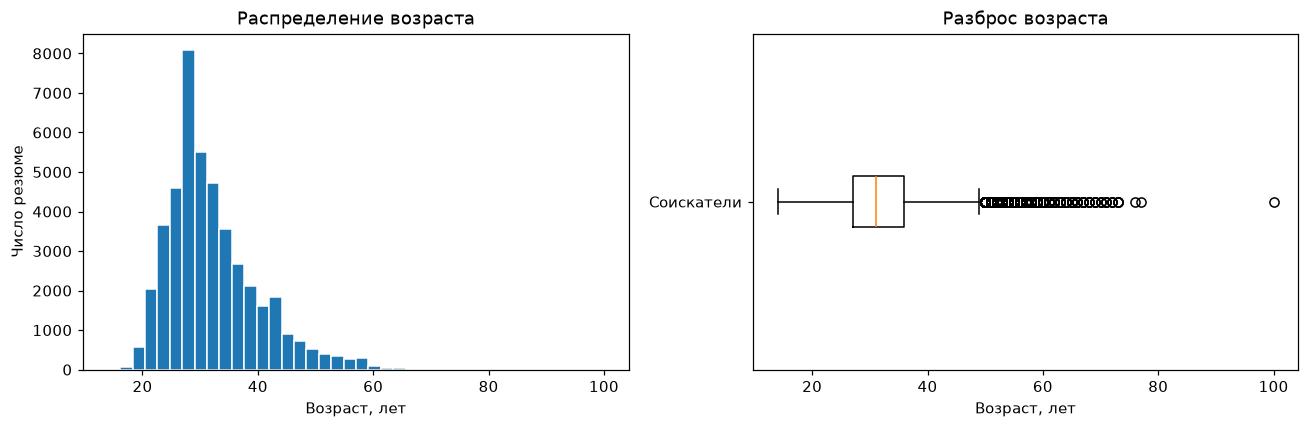

In [13]:
age = df['Возраст']
print('Мода:', age.mode().iloc[0])
print('Минимум и максимум:', age.min(), age.max())
print('Квартили:', age.quantile([0.25, 0.5, 0.75]).to_dict())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(age, bins=40, edgecolor='white')
axes[0].set(title='Распределение возраста', xlabel='Возраст, лет', ylabel='Число резюме')
axes[1].boxplot(age, vert=False)
axes[1].set(title='Разброс возраста', xlabel='Возраст, лет', yticks=[1], yticklabels=['Соискатели'])
plt.tight_layout(); plt.show()

Возраст чаще всего равен 30 годам. Центральные 50% значений находятся между 27 и 36 годами. Большинство наблюдений сосредоточено в молодом и среднем трудоспособном возрасте. Возраст 100 лет выглядит подозрительно и требует проверки; редкие наблюдения сами по себе не доказывают ошибку.

2. Постройте распределение признака **"Опыт работы (месяц)"**. Опишите данное распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится опыт работы большинства соискателей? Есть ли аномалии для признака опыта работы, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

Мода: [81.0]
Минимум и максимум: 1.0 1188.0
Квартили: {0.25: 57.0, 0.5: 100.0, 0.75: 154.0}


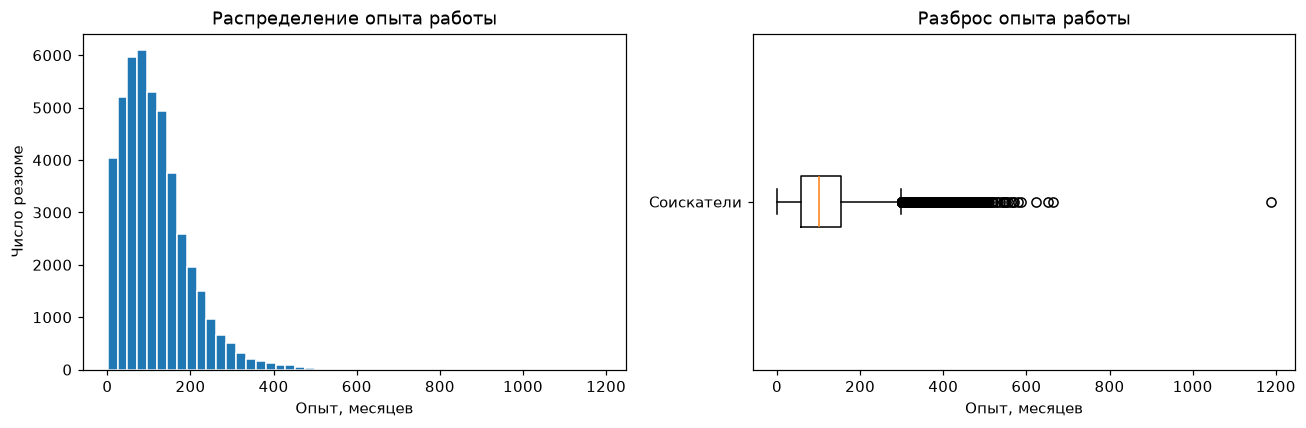

In [14]:
experience = df['Опыт работы (месяц)'].dropna()
print('Мода:', experience.mode().tolist())
print('Минимум и максимум:', experience.min(), experience.max())
print('Квартили:', experience.quantile([0.25, 0.5, 0.75]).to_dict())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(experience, bins=50, edgecolor='white')
axes[0].set(title='Распределение опыта работы', xlabel='Опыт, месяцев', ylabel='Число резюме')
axes[1].boxplot(experience, vert=False)
axes[1].set(title='Разброс опыта работы', xlabel='Опыт, месяцев', yticks=[1], yticklabels=['Соискатели'])
plt.tight_layout(); plt.show()

Распределение опыта имеет длинный правый хвост. Основная часть резюме содержит опыт до 200 месяцев; точные мода, крайние значения и квартили приведены над графиком. Максимум 1188 месяцев равен 99 годам и требует проверки. Для выявления логических ошибок дополнительно сравним стаж с возрастом.

3. Постройте распределение признака **"ЗП (руб)"**. Опишите данное распределение, отвечая на следующие вопросы: каковы предельные значения признака, в каком примерном интервале находится заработная плата большинства соискателей? Есть ли аномалии для признака возраста? Обратите внимание на гигантские размеры желаемой заработной платы.
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*


Минимум и максимум: 1.0 24304876.0
Квартили: {0.25: 37082.2, 0.5: 59019.0, 0.75: 95000.0}
Зарплат выше миллиона: 5


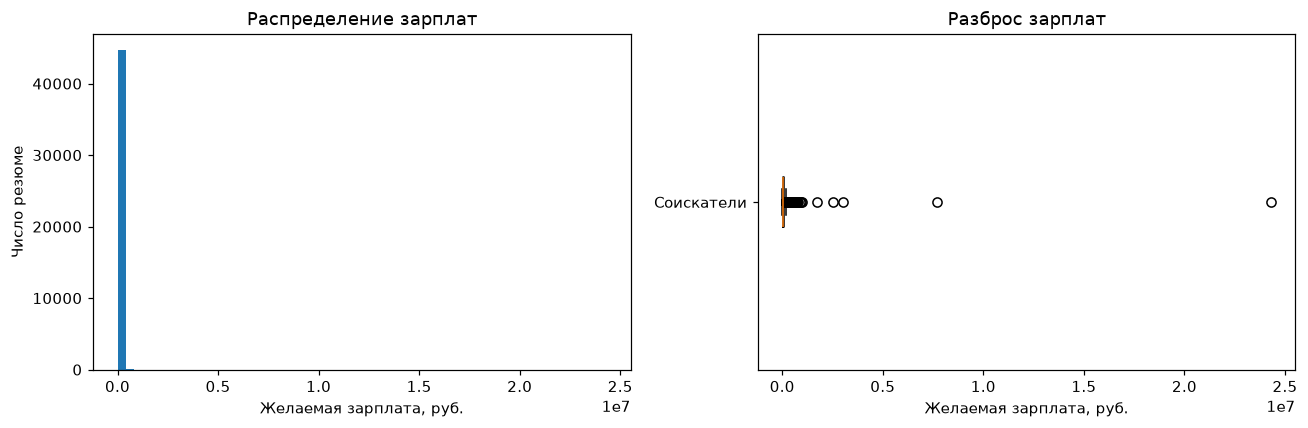

In [15]:
salary = df['ЗП (руб)']
print('Минимум и максимум:', salary.min(), salary.max())
print('Квартили:', salary.quantile([0.25, 0.5, 0.75]).to_dict())
print('Зарплат выше миллиона:', (salary > 1_000_000).sum())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(salary, bins=60)
axes[0].set(title='Распределение зарплат', xlabel='Желаемая зарплата, руб.', ylabel='Число резюме')
axes[1].boxplot(salary, vert=False)
axes[1].set(title='Разброс зарплат', xlabel='Желаемая зарплата, руб.', yticks=[1], yticklabels=['Соискатели'])
plt.tight_layout(); plt.show()
plot_df = df.loc[df['ЗП (руб)'] < 1_000_000].copy()

Зарплаты имеют выраженную правостороннюю асимметрию. Медиана составляет около 59 тысяч рублей; пять запросов выше миллиона растягивают масштаб. Значения меньше тысячи рублей и многомиллионные запросы выглядят аномально. В следующих сравнениях используем временную выборку зарплат менее миллиона, не удаляя строки из основной таблицы.

4. Постройте диаграмму, которая показывает зависимость **медианной** желаемой заработной платы (**"ЗП (руб)"**) от уровня образования (**"Образование"**). Используйте для диаграммы данные о резюме, где желаемая заработная плата меньше 1 млн рублей.
*Сделайте выводы по представленной диаграмме: для каких уровней образования наблюдаются наибольшие и наименьшие уровни желаемой заработной платы? Как вы считаете, важен ли признак уровня образования при прогнозировании заработной платы?*

Образование
среднее                40000.0
среднее специальное    40000.0
неоконченное высшее    50000.0
высшее                 60000.0
Name: ЗП (руб), dtype: float64


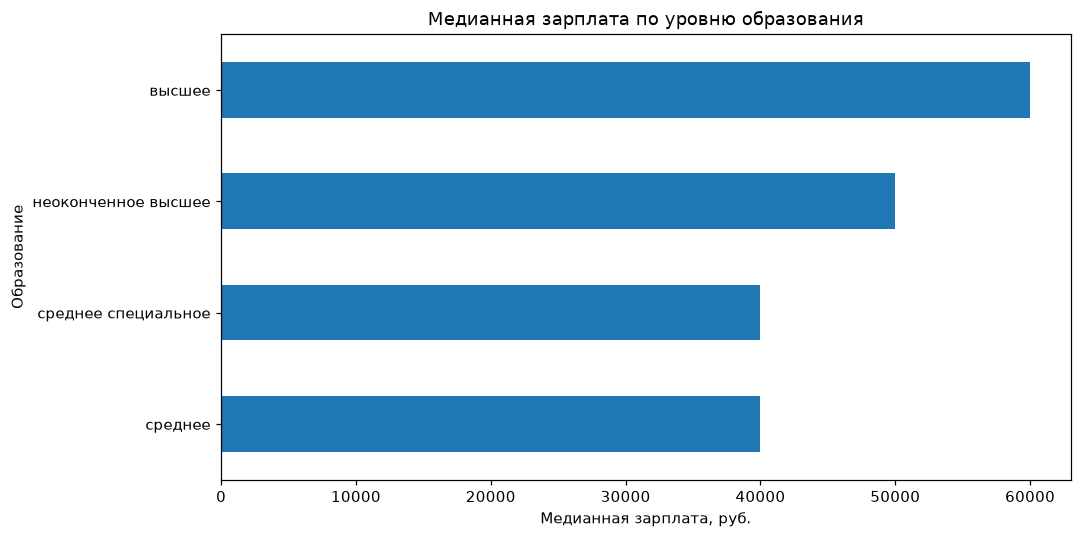

In [16]:
education_salary = plot_df.groupby('Образование')['ЗП (руб)'].median().sort_values()
print(education_salary)
ax = education_salary.plot.barh()
ax.set(title='Медианная зарплата по уровню образования', xlabel='Медианная зарплата, руб.', ylabel='Образование')
plt.tight_layout(); plt.show()

Наибольшая медианная зарплата у соискателей с высшим образованием — 60 тысяч рублей. Наименьшая — у соискателей со средним и средним специальным образованием: 40 тысяч рублей. Признак образования может быть полезен для прогнозирования зарплатных ожиданий, однако различия также могут зависеть от профессии, опыта и города.

5. Постройте диаграмму, которая показывает распределение желаемой заработной платы (**"ЗП (руб)"**) в зависимости от города (**"Город"**). Используйте для диаграммы данные о резюме, где желая заработная плата меньше 1 млн рублей.
*Сделайте выводы по полученной диаграмме: как соотносятся медианные уровни желаемой заработной платы и их размах в городах? Как вы считаете, важен ли признак города при прогнозировании заработной платы?*

                   median  min       max
Город                                   
Москва            85000.0  1.0  900000.0
Санкт-Петербург   60000.0  1.0  645171.0
город-миллионник  40000.0  1.0  511681.6
другие            40000.0  1.0  923983.0
Категория с максимальной зарплатой: другие


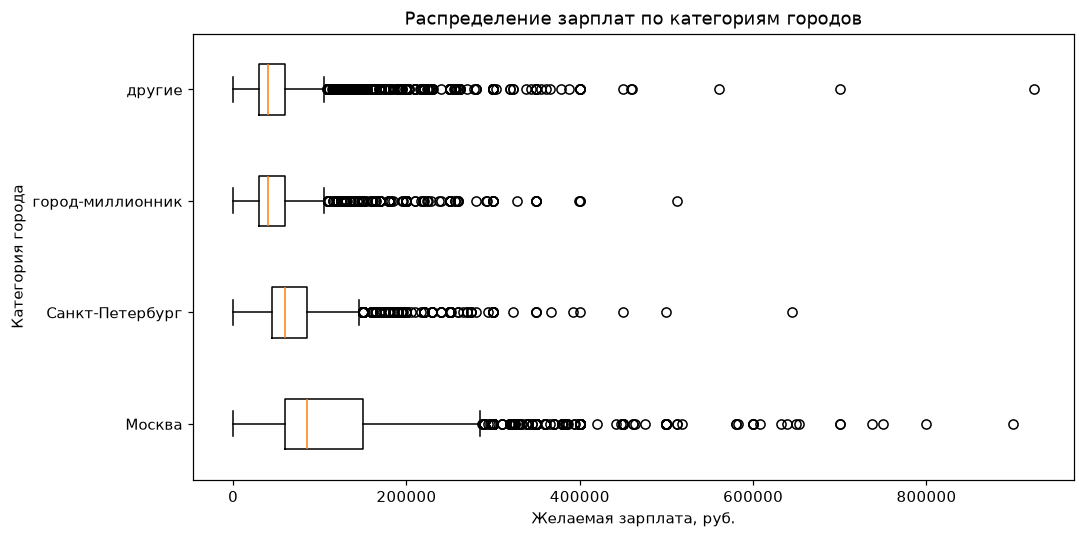

In [17]:
city_stats = plot_df.groupby('Город')['ЗП (руб)'].agg(['median', 'min', 'max'])
print(city_stats)
cities = city_stats.index.tolist()
fig, ax = plt.subplots()
ax.boxplot([plot_df.loc[plot_df['Город'].eq(city), 'ЗП (руб)'] for city in cities], tick_labels=cities, vert=False)
ax.set(title='Распределение зарплат по категориям городов', xlabel='Желаемая зарплата, руб.', ylabel='Категория города')
plt.tight_layout(); plt.show()
print('Категория с максимальной зарплатой:', city_stats['max'].idxmax())

Наибольшая медианная зарплата наблюдается в Москве; в Санкт-Петербурге она ниже, а в городах-миллионниках и других городах — ещё ниже. Разброс запросов во всех группах велик, и присутствуют высокие отдельные значения. Максимальный запрос в выборке менее миллиона находится в категории «другие» и составляет около 924 тысяч рублей. Город полезен для прогноза, поскольку связан с различиями в уровне зарплатных ожиданий.

6. Постройте **многоуровневую столбчатую диаграмму**, которая показывает зависимость медианной заработной платы (**"ЗП (руб)"**) от признаков **"Готовность к переезду"** и **"Готовность к командировкам"**. Проанализируйте график, сравнив уровень заработной платы в категориях.

Готовность к командировкам    False      True 
Готовность к переезду                         
False                       40000.0  60000.000
True                        50000.0  65849.455
Готовы к обоим, тыс. руб.: 66


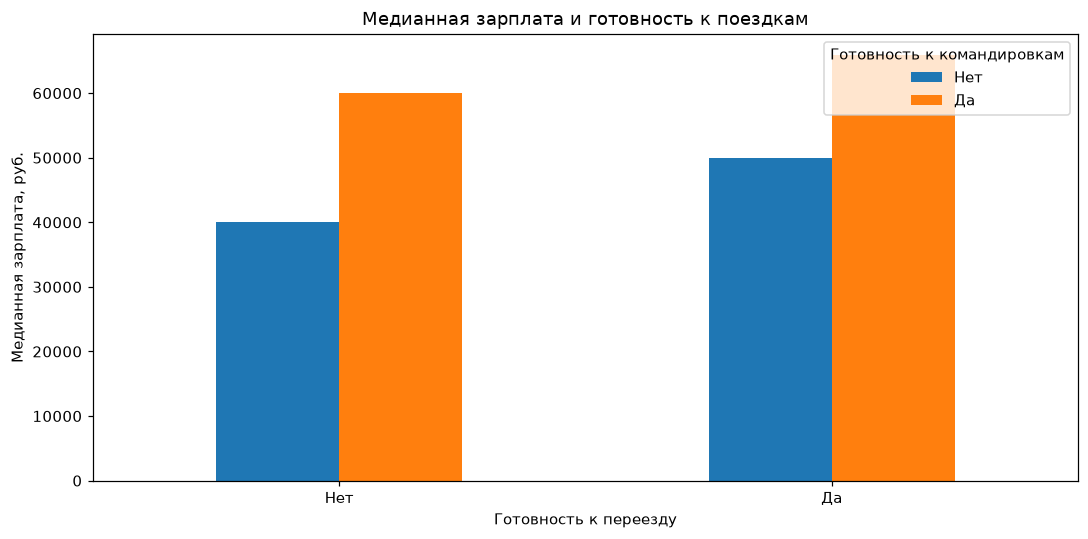

In [18]:
mobility_salary = df.groupby(['Готовность к переезду', 'Готовность к командировкам'])['ЗП (руб)'].median().unstack()
print(mobility_salary)
ax = mobility_salary.rename(index={False: 'Нет', True: 'Да'}, columns={False: 'Нет', True: 'Да'}).plot.bar(rot=0)
ax.set(title='Медианная зарплата и готовность к поездкам', xlabel='Готовность к переезду', ylabel='Медианная зарплата, руб.')
ax.legend(title='Готовность к командировкам')
plt.tight_layout(); plt.show()
print('Готовы к обоим, тыс. руб.:', round(mobility_salary.loc[True, True] / 1000))

Готовность к командировкам и переезду связана с более высокими зарплатными ожиданиями. Для соискателей, готовых к обоим вариантам, медиана составляет 66 тысяч рублей. Сравнение групп описывает связь признаков, но не позволяет сделать вывод, что сама готовность к переезду повышает зарплату.

7. Постройте сводную таблицу, иллюстрирующую зависимость **медианной** желаемой заработной платы от возраста (**"Возраст"**) и образования (**"Образование"**). На полученной сводной таблице постройте **тепловую карту**. Проанализируйте тепловую карту, сравнив показатели внутри групп.

Возраст                  14       15         16   ...      76       77       100
Образование                                       ...                           
высшее               60000.0      NaN  122582.49  ...  45000.0  90000.0      NaN
неоконченное высшее      NaN      NaN        NaN  ...      NaN      NaN      NaN
среднее                  NaN  10000.0        NaN  ...      NaN      NaN      NaN
среднее специальное      NaN   2000.0   30000.00  ...      NaN      NaN  60000.0

[4 rows x 63 columns]

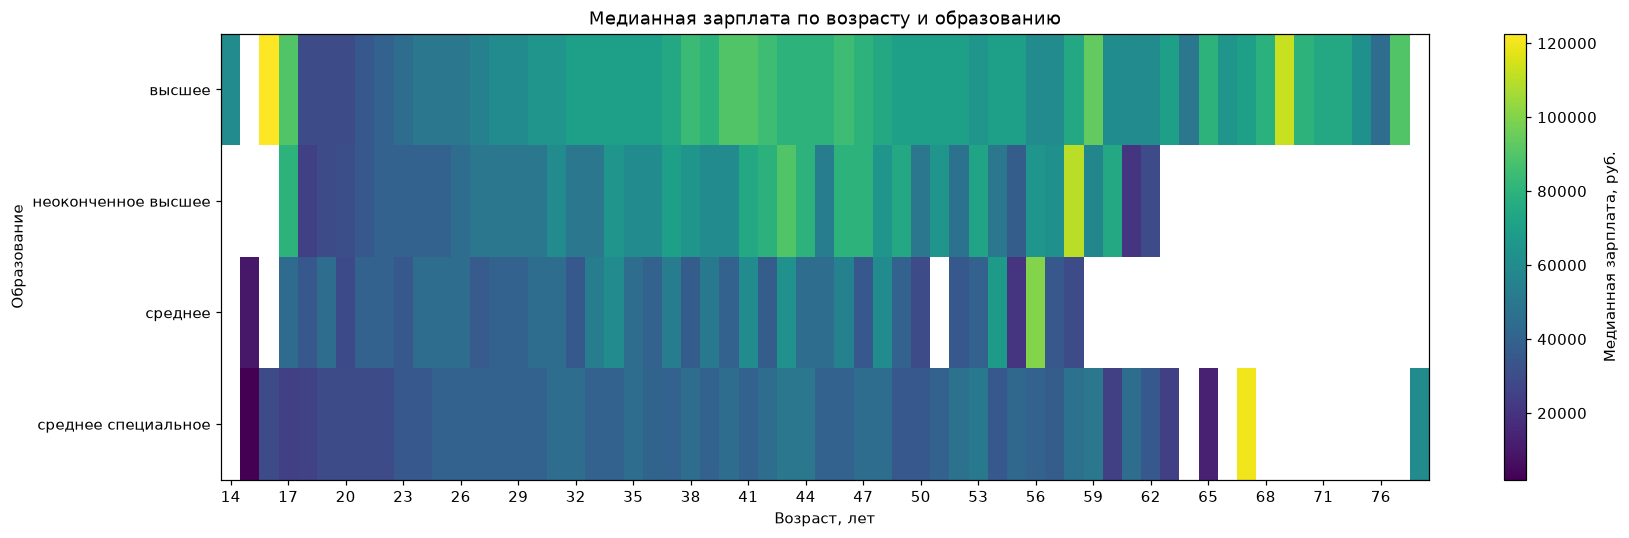

In [19]:
education_age = df.pivot_table(index='Образование', columns='Возраст', values='ЗП (руб)', aggfunc='median')
display(education_age)
fig, ax = plt.subplots(figsize=(16, 5))
image = ax.imshow(education_age, aspect='auto', cmap='viridis')
ax.set_yticks(range(len(education_age.index)), education_age.index)
positions = np.arange(0, len(education_age.columns), 3)
ax.set_xticks(positions, education_age.columns[positions])
ax.set(title='Медианная зарплата по возрасту и образованию', xlabel='Возраст, лет', ylabel='Образование')
fig.colorbar(image, ax=ax, label='Медианная зарплата, руб.')
plt.tight_layout(); plt.show()

В группах высшего и неоконченного высшего образования зарплатные ожидания заметнее увеличиваются от молодого возраста к среднему. При среднем и среднем специальном образовании рост слабее. В старших возрастах отдельные клетки могут опираться на малое число резюме, поэтому резкие скачки нельзя считать устойчивой закономерностью. Среди рассматриваемых групп наиболее выраженный рост виден у высшего образования.

8. Постройте **диаграмму рассеяния**, показывающую зависимость опыта работы (**"Опыт работы (месяц)"**) от возраста (**"Возраст"**). Опыт работы переведите из месяцев в года, чтобы признаки были в едином масштабе. Постройте на графике дополнительно прямую, проходящую через точки (0, 0) и (100, 100). Данная прямая соответствует значениям, когда опыт работы равен возрасту человека. Точки, лежащие на этой прямой и выше нее - аномалии в наших данных (опыт работы больше либо равен возрасту соискателя)

Опыт строго больше возраста: 7


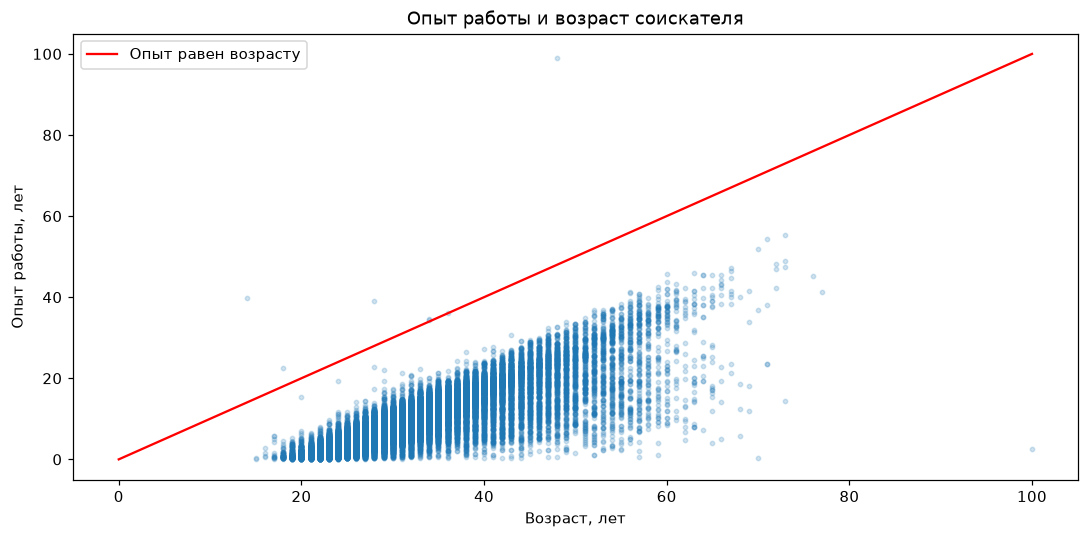

In [20]:
experience_years = df['Опыт работы (месяц)'] / 12
fig, ax = plt.subplots()
ax.scatter(df['Возраст'], experience_years, s=8, alpha=0.2)
ax.plot([0, 100], [0, 100], color='red', label='Опыт равен возрасту')
ax.set(title='Опыт работы и возраст соискателя', xlabel='Возраст, лет', ylabel='Опыт работы, лет')
ax.legend(); plt.tight_layout(); plt.show()
print('Опыт строго больше возраста:', (experience_years > df['Возраст']).sum())

В основном опыт увеличивается вместе с возрастом и остаётся ниже линии равенства. Выше этой линии находятся семь резюме: их опыт превышает возраст, что логически невозможно. Такие записи удалим на этапе очистки. Даже часть точек ниже линии может требовать проверки, если подразумевает неправдоподобно раннее начало работы.

**Дополнительные баллы**

Для получения 2 дополнительных баллов по разведывательному анализу постройте еще два любых содержательных графика или диаграммы, которые помогут проиллюстрировать влияние признаков/взаимосвязь между признаками/распределения признаков. Приведите выводы по ним. Желательно, чтобы в анализе участвовали признаки, которые мы создавали ранее в разделе "Преобразование данных".


Медианы зарплаты:
Пол                     Ж        М
Город                             
Москва            70000.0  90000.0
Санкт-Петербург   50000.0  60000.0
город-миллионник  35000.0  45000.0
другие            30632.0  45000.0
Доля удалённой работы, %:
Город
Москва              31.339871
город-миллионник    33.578833
Санкт-Петербург     34.859226
другие              35.511543
Name: удаленная работа, dtype: float64


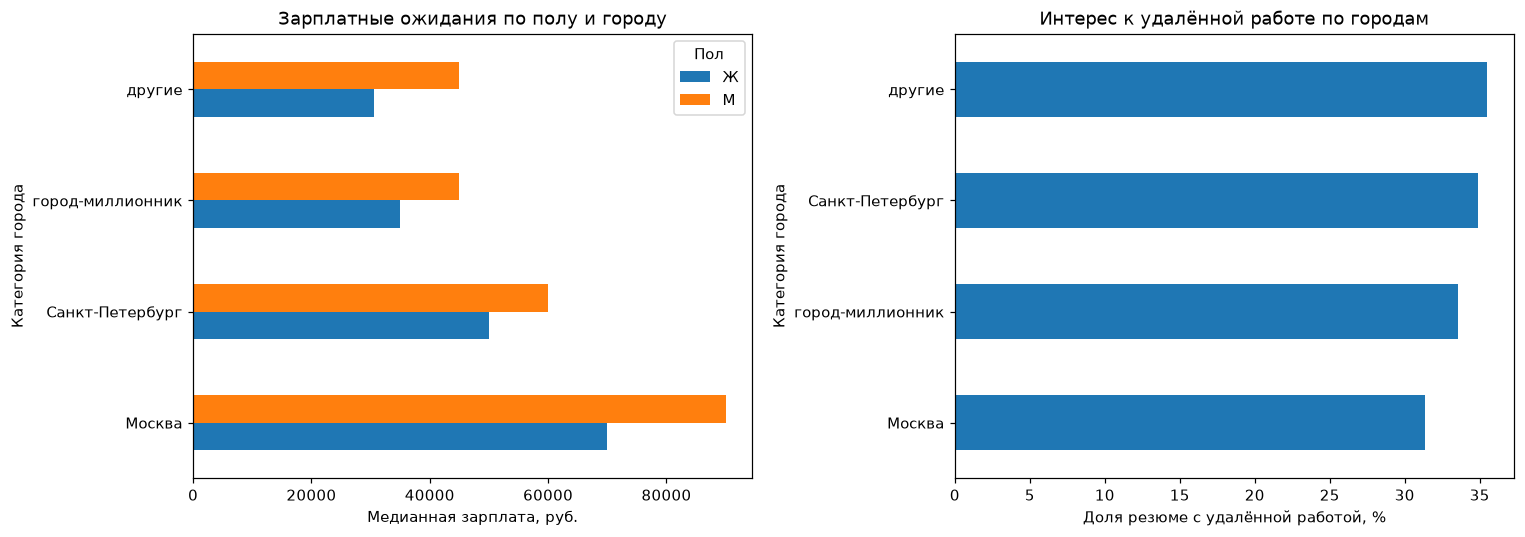

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
gender_salary = plot_df.groupby(['Город', 'Пол'])['ЗП (руб)'].median().unstack()
gender_salary.plot.barh(ax=axes[0])
axes[0].set(title='Зарплатные ожидания по полу и городу', xlabel='Медианная зарплата, руб.', ylabel='Категория города')
remote_share = df.groupby('Город')['удаленная работа'].mean().mul(100).sort_values()
remote_share.plot.barh(ax=axes[1])
axes[1].set(title='Интерес к удалённой работе по городам', xlabel='Доля резюме с удалённой работой, %', ylabel='Категория города')
plt.tight_layout(); plt.show()
print('Медианы зарплаты:'); print(gender_salary)
print('Доля удалённой работы, %:'); print(remote_share)

Первый график показывает различия медианных зарплатных ожиданий мужчин и женщин внутри категорий городов. Сравнение внутри города уменьшает влияние географии, но не учитывает различия профессий, опыта и занятости, поэтому причинные выводы делать нельзя. Второй график показывает, что интерес к удалённой работе встречается во всех категориях городов, а его доля различается. Этот признак описывает предпочтения соискателя, а не фактический формат текущей работы.

# Очистка данных

1. Начнем с дубликатов в наших данных. Найдите **полные дубликаты** в таблице с резюме и удалите их. 

In [22]:
answers = {}
answers['5.1'] = int(df.duplicated().sum())
print('Дубликатов:', answers['5.1'])
assert answers['5.1'] == 161
df = df.drop_duplicates().copy()
print('Осталось строк:', len(df))

Дубликатов: 161
Осталось строк: 44583


2. Займемся пропусками. Выведите информацию **о числе пропусков** в столбцах. 

In [23]:
display(df.isna().sum().to_frame('Число пропусков'))
answers['5.2'] = int(df['Опыт работы (месяц)'].isna().sum())
print('Пропусков опыта:', answers['5.2'])
assert answers['5.2'] == 168

Пропусков опыта: 168


                                 Число пропусков
Ищет работу на должность:                      0
Последнее/нынешнее место работы                1
Последняя/нынешняя должность                   2
Обновление резюме                              0
Авто                                           0
Образование                                    0
Пол                                            0
Возраст                                        0
Опыт работы (месяц)                          168
Город                                          0
Готовность к переезду                          0
Готовность к командировкам                     0
полная занятость                               0
частичная занятость                            0
проектная работа                               0
стажировка                                     0
волонтерство                                   0
полный день                                    0
сменный график                                 0
гибкий график       

3. Итак, у нас есть пропуски в 3ех столбцах: **"Опыт работы (месяц)"**, **"Последнее/нынешнее место работы"**, **"Последняя/нынешняя должность"**. Поступим следующим образом: удалите строки, где есть пропуск в столбцах с местом работы и должностью. Пропуски в столбце с опытом работы заполните **медианным** значением.

In [24]:
df = df.dropna(subset=['Последнее/нынешнее место работы', 'Последняя/нынешняя должность']).copy()
median_experience = df['Опыт работы (месяц)'].median()
df['Опыт работы (месяц)'] = df['Опыт работы (месяц)'].fillna(median_experience)
answers['5.3'] = round(df['Опыт работы (месяц)'].mean())
print('Среднее:', df['Опыт работы (месяц)'].mean())
print('Округлённое:', answers['5.3'])
assert answers['5.3'] == 114

Среднее: 114.35777573405711
Округлённое: 114


4. Мы добрались до ликвидации выбросов. Сначала очистим данные вручную. Удалите резюме, в которых указана заработная плата либо выше 1 млн. рублей, либо ниже 1 тыс. рублей.

In [25]:
mask = (df['ЗП (руб)'] < 1000) | (df['ЗП (руб)'] > 1_000_000)
answers['5.4'] = int(mask.sum())
print('Выбросов:', answers['5.4'])
assert answers['5.4'] == 89
df = df.loc[~mask].copy()
print('Осталось строк:', len(df))

Выбросов: 89
Осталось строк: 44492


5. В процессе разведывательного анализа мы обнаружили резюме, в которых **опыт работы в годах превышал возраст соискателя**. Найдите такие резюме и удалите их из данных


In [26]:
mask = df['Опыт работы (месяц)'] / 12 > df['Возраст']
answers['5.5'] = int(mask.sum())
print('Выбросов:', answers['5.5'])
assert answers['5.5'] == 7
df = df.loc[~mask].copy()
print('Осталось строк:', len(df))

Выбросов: 7
Осталось строк: 44485


6. В результате анализа мы обнаружили потенциальные выбросы в признаке **"Возраст"**. Это оказались резюме людей чересчур преклонного возраста для поиска работы. Попробуйте построить распределение признака в **логарифмическом масштабе**. Добавьте к графику линии, отображающие **среднее и границы интервала метода трех сигм**. Напомним, сделать это можно с помощью метода axvline. Например, для построение линии среднего будет иметь вид:

`histplot.axvline(log_age.mean(), color='k', lw=2)`

В какую сторону асимметрично логарифмическое распределение? Напишите об этом в комментарии к графику.
Найдите выбросы с помощью метода z-отклонения и удалите их из данных, используйте логарифмический масштаб. Давайте сделаем послабление на **1 сигму** (возьмите 4 сигмы) в **правую сторону**.

Выведите таблицу с полученными выбросами и оцените, с каким возрастом соискатели попадают под категорию выбросов?

Асимметрия: 0.4523422276053838
Границы в годах: 15.65944146864924 78.87868555320016
Выбросов: 3
Итоговое число строк: 44482


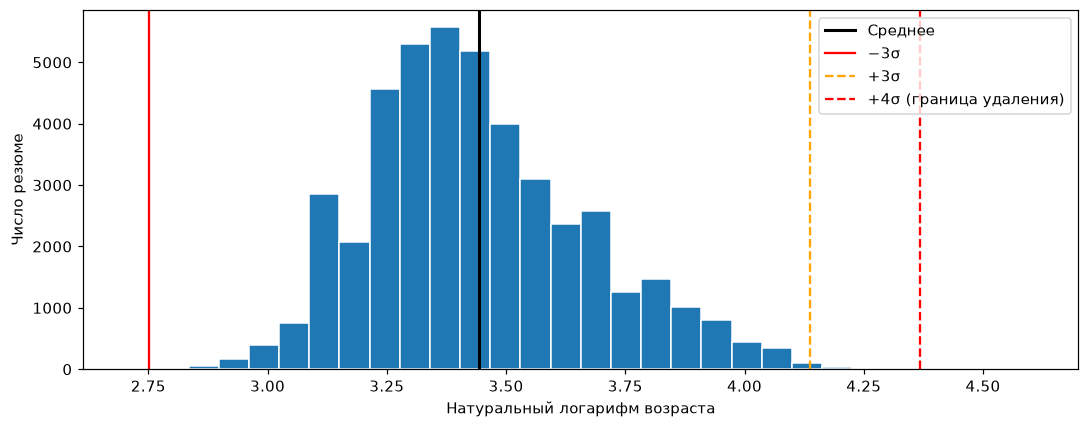

            Ищет работу на должность:  ... ЗП (руб)
31137  Менеджер по работе с клиентами  ...  10000.0
32950                 Тестировщик игр  ...   2000.0
33654            Frontend-разработчик  ...  60000.0

[3 rows x 23 columns]

In [27]:
log_age = np.log(df['Возраст'])
mean, std = log_age.mean(), log_age.std()
lower, upper = mean - 3 * std, mean + 4 * std
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(log_age, bins=30, edgecolor='white')
ax.axvline(mean, color='k', lw=2, label='Среднее')
ax.axvline(mean - 3*std, color='red', label='−3σ')
ax.axvline(mean + 3*std, color='orange', linestyle='--', label='+3σ')
ax.axvline(upper, color='red', linestyle='--', label='+4σ (граница удаления)')
ax.set(xlabel='Натуральный логарифм возраста', ylabel='Число резюме')
ax.legend(); plt.tight_layout(); plt.show()
print('Асимметрия:', log_age.skew())
print('Границы в годах:', np.exp(lower), np.exp(upper))
mask = (log_age < lower) | (log_age > upper)
display(df.loc[mask])
answers['5.6'] = int(mask.sum())
print('Выбросов:', answers['5.6'])
assert answers['5.6'] == 3
df = df.loc[~mask].copy()
assert len(df) == 44482
print('Итоговое число строк:', len(df))

Логарифмическое распределение возраста имеет правостороннюю асимметрию: коэффициент около 0,45. Используем нижнюю границу −3σ и верхнюю +4σ. Выбросами становятся два резюме с возрастом 15 лет и одно — 100 лет. После удаления остаётся 44 482 строки. Применённое статистическое правило не доказывает ошибку в возрасте, но выполняет условие очистки.

In [28]:
display(pd.Series(answers, name='Ответ').to_frame())
assert not df.isna().any().any()
assert not df.duplicated().any()
df.to_csv('data/hh_cleaned.csv', sep=';', index=False)


     Ответ
5.1    161
5.2    168
5.3    114
5.4     89
5.5      7
5.6      3